# 03 SD visual - latente 64x64 vs pixel 512x512 (punto 3)


Consigna: extraer tensores manualmente con diffusers, ver VAE + UNet + texto. Requiere HF token para SD v1.5.


### Setup (apuntes REPOS 3.2: solo diffusers+transformers)
Instalamos lo minimo. Ver REPOS_ESTADO 3.1.


In [1]:
%pip install -q diffusers transformers accelerate
import torch
print(torch.cuda.is_available())


True


### Token HF (apuntes NOTAS 05 LDM)
SD v1.5 es gated. Sin token da 401. Pon HF_TOKEN en Secrets Colab.


In [2]:
from huggingface_hub import login
import os
tok=os.environ.get("HF_TOKEN","")
print("token:", "si" if tok else "usa login o Secrets")
 # en Colab: from google.colab import userdata; login(userdata.get("HF_TOKEN"))


token: usa login o Secrets


### Componentes SD (apuntes NOTAS 05 + paper 2112.10752)
VAE f=8 comprime 512->64, UNet denoisea en latente, CLIP 77x768 condiciona por cross-attn, scheduler DDIM 50.


In [3]:
import torch
from diffusers import StableDiffusionPipeline
pipe=StableDiffusionPipeline.from_pretrained("stable-diffusion-v1-5/stable-diffusion-v1-5", torch_dtype=torch.float16, use_auth_token=True)
pipe.to("cuda" if torch.cuda.is_available() else "cpu")
print("componentes:", list(pipe.components.keys()))
print("VAE:", pipe.vae.config.sample_size, "UNet:", pipe.unet.config.sample_size)


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Keyword arguments {'use_auth_token': True} are not expected by StableDiffusionPipeline and will be ignored.


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

componentes: ['vae', 'text_encoder', 'tokenizer', 'unet', 'scheduler', 'safety_checker', 'feature_extractor', 'image_encoder']
VAE: 512 UNet: 64


### Generacion + extraccion manual (apuntes NOTAS punto3)
Callback guarda latents (1,4,64,64) cada step. Es el tensor manual que pide la consigna.


  0%|          | 0/50 [00:00<?, ?it/s]

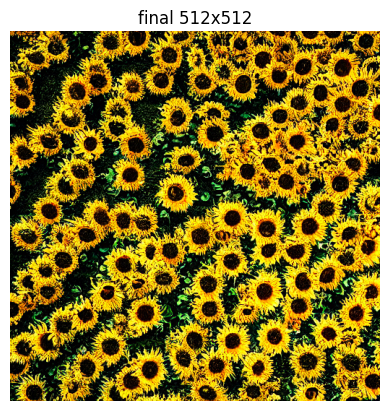

steps guardados: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] lat shape: torch.Size([1, 4, 64, 64])


In [4]:
prompt="a close-up photo of a sunflower field, high detail"
import torch, matplotlib.pyplot as plt, numpy as np
saved={}
def cb(pipe, step, t, cb_kwargs):
    lat=cb_kwargs["latents"]
    saved[step]=lat.detach().float().cpu()
    return cb_kwargs
img=pipe(prompt, num_inference_steps=50, guidance_scale=7.5, callback_on_step_end=cb, callback_on_step_end_inputs=["latents"]).images[0]
plt.imshow(img); plt.title("final 512x512"); plt.axis("off"); plt.show()
print("steps guardados:", sorted(saved.keys())[:10], "lat shape:", list(saved.values())[0].shape)


### Latente vs pixel (consigna punto3 + NOTAS 05)
Heatmap promedio 4 canales 64x64 arriba, decode VAE abajo 512x512. f=8: 64*8=512.


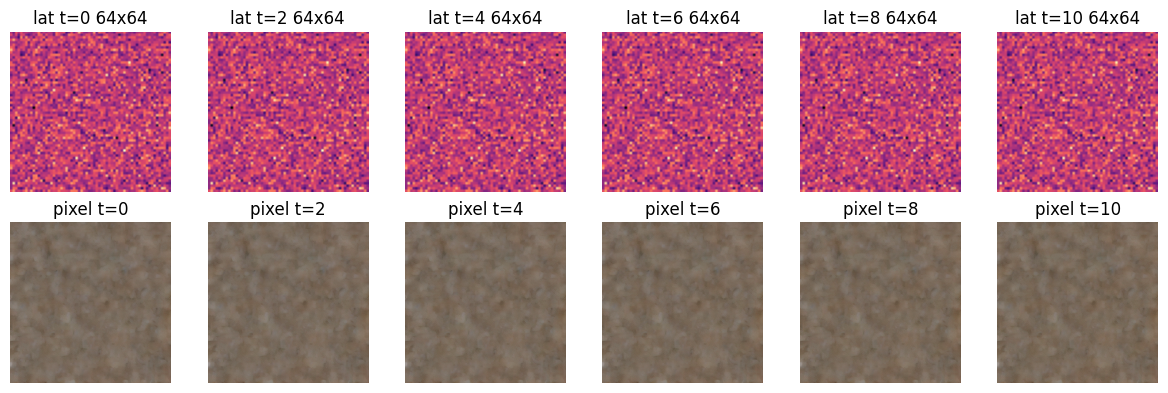

ponytail: factor VAE f=8, 64*8=512


In [5]:
# latente 64x64x4 vs pixel: promedia 4 canales -> heatmap + decode por VAE
import torch, matplotlib.pyplot as plt
steps=sorted(saved.keys())[::2][:6]
plt.figure(figsize=(12,4))
k=0
import torch as T
for s in steps:
    lat=saved[s][0]
    hm=lat.mean(0).numpy()
    plt.subplot(2,6,k+1); plt.imshow(hm, cmap="magma"); plt.title(f"lat t={s} 64x64"); plt.axis("off")
    with T.no_grad():
        dec=pipe.vae.decode(lat.unsqueeze(0).to(pipe.vae.dtype).to(pipe.device)).sample[0].float().cpu()
        dec=(dec/2+0.5).clamp(0,1).permute(1,2,0).numpy()
    plt.subplot(2,6,k+7); plt.imshow(dec); plt.title(f"pixel t={s}"); plt.axis("off")
    k+=1
plt.tight_layout(); plt.show()
print("ponytail: factor VAE f=8, 64*8=512")


### Texto -> UNet (apuntes NOTAS 06 CFG + 23 SD3)
Tokens 77 + emb 77x768 entran a UNet por cross-attention. guidance_scale=7.5.


tokens: torch.Size([1, 77])
text_emb: (1, 77, 768) -> entra a UNet via cross-attn


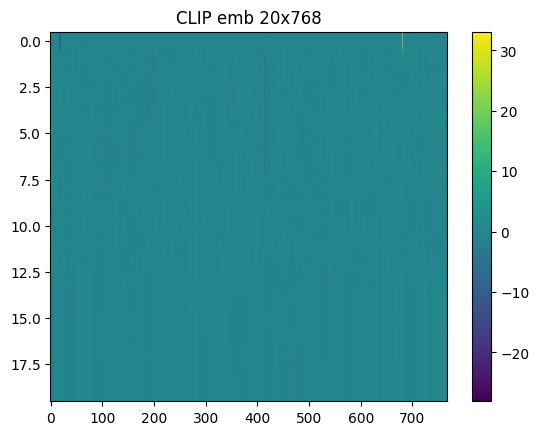

In [6]:
# tensores texto: CLIP -> UNet cross-attention
toks=pipe.tokenizer(prompt, padding="max_length", max_length=77, return_tensors="pt")
print("tokens:", toks.input_ids.shape)
emb=pipe.text_encoder(toks.input_ids.to(pipe.device))[0]
print("text_emb:", tuple(emb.shape), "-> entra a UNet via cross-attn")
import matplotlib.pyplot as plt
plt.imshow(emb[0,:20,:].detach().float().cpu().numpy(), aspect="auto"); plt.title("CLIP emb 20x768"); plt.colorbar(); plt.show()


### Proceso (consigna: visualizar proceso)
Norma latente vs step: ruido->senal. Complementa grid 6 pasos.


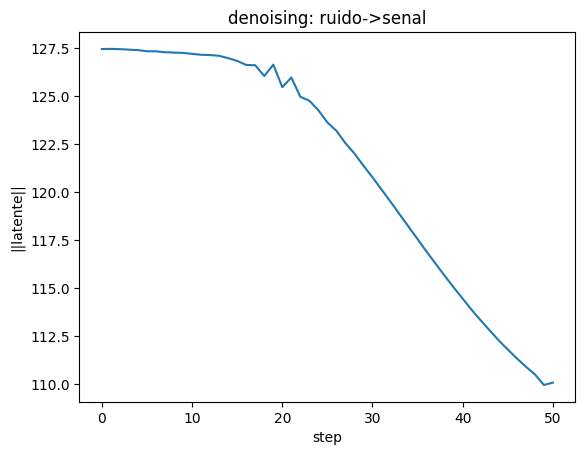

In [7]:
# curva denoising: norma del latente vs step
import matplotlib.pyplot as plt
xs=sorted(saved.keys())
ys=[float(saved[s].norm()) for s in xs]
plt.plot(xs,ys); plt.xlabel("step"); plt.ylabel("||latente||"); plt.title("denoising: ruido->senal"); plt.show()


## Para informe: VAE comprime 512->64 (f=8), UNet denoisea en latente, texto via CLIP. DDIM 50 steps.
